# Generate astrophysical factor 2D maps
This notebook describes how to generate a `gammapy` 2D maps of the astrophysical factor previously generated with `CLUMPY`.

Authors: Gonzalo Rodriguez Fernandez gonzalo.rodriguez.fernandez@roma2.infn.it, Michele Doro michele.doro@unipd.it

Last update: 2024.03.01

`CLUMPY` is a public code that allows to estimate DM astrophysical factor profiles solving the Jean equations. As an output of the analysis with `CLUMPY` one should have at hand several information
- a radial profile of the astrophysical factor integrated within a certain rsky. This can be computed for different stellar models (e.g. King) or different DM profile models (e.g. Einasto, Burkert). The radial profile changes accordingly.
- the target distance [kpc]
- the target tidal radii, computed according to the specific DM profile used

Two relevant output files are used for this work
- astrophysical factors within a certain integration angle (including 1-2sigma bands) called `Jalphaint.dat` or ``Dalphaint.dat`` file (former for annihilating DM, latter for decaying DM)
- 2Dmaps of the astrophysical factors cut at the tidal radius called e.g. `annihil_Wil12D_FOVdiameter10.0deg_nside1024.fits`

Some of these files needs to be elaborated for usage with `gammapy`

## Convert 2Dmaps
2Dmaps in `.fits` format should be converted. In order to do this one needs to
- install `healpy` and `reproject`
- find the file `makeFitsImage.py` from the `CLUMPY` repository https://gitlab.com/clumpy/CLUMPY/-/blob/master/python_helperscripts/makeFitsImage.py

In [1]:
# Run
#profile_file = "annihil_Wil12D_FOVdiameter10.0deg_nside1024.fits"
#!python makeFitsImage.py -i  profilefile --extension 1 --column 1

This script will generate a file 
`annihil_Wil12D_FOVdiameter10.0deg_nside1024-JFACTOR-Jtot-image.fits` which is to be later used in this analysis

# General imports and starting data-set
You need `gammapy` and other basic packages

In [2]:
# We should clean those that are not needed

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib as mpl
from matplotlib.patches import Circle

# %matplotlib inline

from scipy.interpolate import interp1d

import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy import units as u
from astropy.coordinates import SkyCoord

from IPython.display import display

from gammapy.data import Observation, observatory_locations
from gammapy.datasets import MapDataset
##from gammapy.irf import load_cta_irfs
#from gammapy.irf import load_irf_dict_from_file
from gammapy.makers import MapDatasetMaker, SafeMaskMaker
from gammapy.maps import MapAxis, WcsGeom
from gammapy.maps import Map
from gammapy.modeling import Fit


from gammapy.modeling.models import (
    FoVBackgroundModel,
    GaussianSpatialModel,
    TemplateSpatialModel,
    Models,
    PowerLawSpectralModel,
    SkyModel,
)
from gammapy.astro.darkmatter import DarkMatterAnnihilationSpectralModel

For the CTA KSP paper we have narrowed down the best dSPh targets. This notebook describe the analysis for:
- Complete Names = ['Coma Berenices', 'Draco', 'Reticulum II', "Sculptor", 'Sagittarius II', 'Ursa Major II Galaxy','Ursa Minor', 'Willman 1']
- Short names: ['CBe','DraI','RetII', 'Scl', 'SgrII', 'UMaII', 'UMi', 'Wil1']

we have generated:
- annihilation and decay profiles (called `Jann` and `Jdec` instead of `J` and `D`)
- cusp (Einasto) and cored (Burkert) profiles, see text

In [3]:
# We start by listing some dsph parameters and define useful arrays

df_input = pd.read_csv('2Dmaps_dsph_parameters.csv')

# dSph names
completeName = df_input['completeName'].values 
dSphNames = df_input['dSphNames'].values 

# Other parameters
# - distance kpc
# - Rtidal_einasto: tidal radius according to Einasto profile in kpc
# - Rtidal_burkert: tidal radius according to Burkert profile in kpc
distance       = df_input['distance'].values 
Rtidal_einasto = df_input['Rtidal_einasto'].values 
Rtidal_burkert = df_input['Rtidal_burkert'].values 
alpha_opt      = df_input['alpha_opt'].values 

# Express in degrees
alpha_tidal = np.rad2deg(np.arctan(np.divide(Rtidal_einasto,distance)))

for name, D, rt_ein, rt_bur, a_opt, a_tid in zip(dSphNames, distance, Rtidal_einasto, Rtidal_burkert, alpha_opt, alpha_tidal):
    print("{:<6}: D={} kpc, rtE={:5.2f} kpc, rtB={:5.2f} kpc, Aopt={:.2f} deg, Atid={:5.2f} deg".format(name, D,rt_ein,rt_bur,a_opt,a_tid))

CBe   : D=42 kpc, rtE= 6.30 kpc, rtB=19.00 kpc, Aopt=0.20 deg, Atid= 8.53 deg
DraI  : D=75 kpc, rtE= 4.83 kpc, rtB= 4.30 kpc, Aopt=0.23 deg, Atid= 3.68 deg
RetII : D=32 kpc, rtE= 1.70 kpc, rtB= 5.80 kpc, Aopt=0.15 deg, Atid= 3.04 deg
Scl   : D=84 kpc, rtE= 2.95 kpc, rtB= 3.71 kpc, Aopt=0.29 deg, Atid= 2.01 deg
SgrII : D=67 kpc, rtE= 3.70 kpc, rtB= 4.20 kpc, Aopt=0.06 deg, Atid= 3.16 deg
UMaII : D=38 kpc, rtE= 2.10 kpc, rtB= 2.20 kpc, Aopt=0.09 deg, Atid= 3.16 deg
UMi   : D=78 kpc, rtE=14.70 kpc, rtB=15.30 kpc, Aopt=0.57 deg, Atid=10.67 deg
Wil1  : D=43 kpc, rtE= 1.20 kpc, rtB= 1.35 kpc, Aopt=0.08 deg, Atid= 1.60 deg


The next function `jfactor_scale` computes the astrophysical factor and uncertainties according to the `shortname` provided, the `profile` (Einasto, Burkert), and the integration angle `alpha`. This is computed interpolating the binned values generated in the `CLUMPY` file. This function is used only to provide the astrophysical factor units and normalization to the `gammapy` 2D maps to be generated

In [7]:
# Define paths for astrophysical profiles
#path = "../clumpy/Jfactors/profile/Einasto/"
path = "../../clumpy/Jfactors/profile/Burkert/"
#path = "../clumpy/Dfactors/profile/Burkert/"
#!ls -l {path}

# Define paths for astrophysical profiles
#path2d = "../clumpy/Jfactors/2Dmaps/Einasto/"
path2d = "../../clumpy/Jfactors/2Dmaps/Burkert/"
#!ls -l {path2d}

In [8]:
def jfactor_scale(shortname, profile, alpha):

    filename=path+'rvir_'+shortname+'_MCMC.dat.Jalphaint_cls.output'

    df_j = pd.read_csv(filename,
                #delim_whitespace=True,
                sep='\s+',
                header=None,
                comment='#',
                names=['alpha','jfactor','d1','d2','d3','dw1s','up1s','dw2s','up2s'])

    j_inter = interp1d(df_j.alpha.values, df_j.jfactor.values, kind="quadratic")
    j_dw1s  = interp1d(df_j.alpha.values, df_j.dw1s.values, kind="quadratic")
    j_up1s  = interp1d(df_j.alpha.values, df_j.up1s.values, kind="quadratic")

    return np.array([j_inter(alpha), 
                     j_dw1s(alpha), 
                     j_up1s(alpha)])

In [14]:
# It is always better check the output

angles = [0.1,0.5,1,5,10]
profile = "Einasto"
#profile = "Burkert"

for target in dSphNames:
    print("{:<5}: ".format(target), end='')
    for angle in angles:
        norm = jfactor_scale(target, profile, angle)
        print("J<({:.1f})={:.1e} ".format(angle, norm[0]), end=' ')
    print()

CBe  : J<(0.1)=7.5e+18  J<(0.5)=1.8e+20  J<(1.0)=6.0e+20  J<(5.0)=5.6e+21  J<(10.0)=5.7e+21  
DraI : J<(0.1)=1.2e+18  J<(0.5)=5.0e+18  J<(1.0)=5.6e+18  J<(5.0)=5.7e+18  J<(10.0)=5.7e+18  
RetII: J<(0.1)=4.3e+18  J<(0.5)=1.2e+20  J<(1.0)=4.5e+20  J<(5.0)=6.4e+21  J<(10.0)=3.3e+20  
Scl  : J<(0.1)=8.0e+17  J<(0.5)=2.1e+18  J<(1.0)=2.1e+18  J<(5.0)=2.2e+18  J<(10.0)=2.2e+18  
SgrII: J<(0.1)=1.5e+19  J<(0.5)=4.4e+19  J<(1.0)=4.7e+19  J<(5.0)=4.5e+19  J<(10.0)=4.7e+19  
UMaII: J<(0.1)=5.9e+17  J<(0.5)=7.3e+18  J<(1.0)=1.5e+19  J<(5.0)=2.5e+19  J<(10.0)=2.4e+19  
UMi  : J<(0.1)=1.4e+18  J<(0.5)=2.7e+19  J<(1.0)=6.8e+19  J<(5.0)=1.4e+20  J<(10.0)=1.4e+20  
Wil1 : J<(0.1)=1.0e+19  J<(0.5)=2.0e+19  J<(1.0)=2.0e+19  J<(5.0)=2.0e+19  J<(10.0)=2.0e+19  


## Draw a skymap for 1 target
In the following we draw the skymap of the astrophysical factor for one target

In [15]:
#Select target

completename = completeName[0]
shortname = dSphNames[0]

filej=path+'rvir_'+shortname+'_MCMC.dat.Jalphaint_cls.output'
file2d = path2d+'annihil_'+shortname+'2D_FOVdiameter10.0deg_nside1024-JFACTOR-Jtot-image.fits'


CBe   J<(5.0)=5.6e+21 


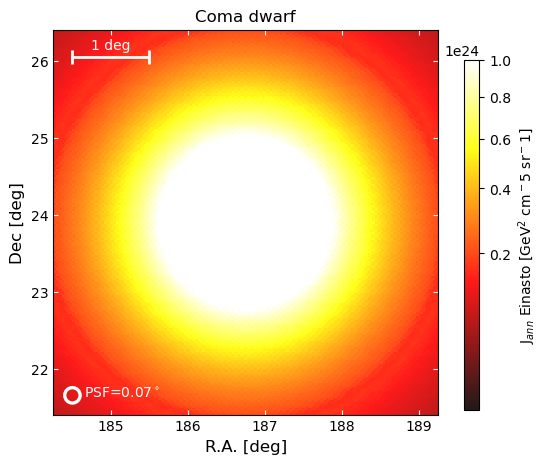

In [16]:
# Read the map file with the `Map` method
m = Map.read(file2d)

# Define the units
m = m.copy(unit="sr^-1")

# Generate a spatial model
spatial_model = TemplateSpatialModel(m, filename=file2d)

# Get the cooordinates of the target and define some skymap extensions
if (completename == completeName[0]):
    coordinates = SkyCoord(ra=186.745833 * u.deg, dec=23.904167 * u.deg, frame='icrs')
else:
    coordinates = SkyCoord.from_name(completename)

center = (coordinates.ra.value, coordinates.dec.value)
ra = coordinates.ra.value
dec = coordinates.dec.value

rsky = 5
ra_mv  = ra - rsky
dec_mv = dec - rsky
ra_Mv  = ra + rsky
dec_Mv = dec + rsky

rzoom = 2.5
ra_mvz  = ra - rzoom
dec_mvz = dec - rzoom
ra_Mvz  = ra + rzoom
dec_Mvz = dec + rzoom


# Compute the normalization of the astrophysical factor to provide units
# Normalization can be done at a radius where the full J/D-factor is enclosed
alpha=5
normalization = np.array(spatial_model.map.data) * jfactor_scale(shortname, profile, alpha)[0]
print("{:<5} J<({:.1f})={:.1e} ".format(shortname, alpha, jfactor_scale(shortname, profile, alpha)[0]))

# Draw skymap for a single source
fig, ax = plt.subplots(1, 1, figsize=(5, 5))

im = ax.imshow(normalization, 
               interpolation="nearest", 
               origin="upper",
               cmap='hot',
               norm=colors.PowerNorm(gamma=0.5, vmin=1e21, vmax=1e24),
               extent=(ra_mv,  ra_Mv, dec_mv,  dec_Mv), 
               alpha=0.9)

#upported values are 'none', 'antialiased', 'nearest', 'bilinear',
#    'bicubic', 'spline16', 'spline36', 'hanning', 'hamming', 'hermite',
#    'kaiser', 'quadric', 'catrom', 'gaussian', 'bessel', 'mitchell',
#    'sinc', 'lanczos', 'blackman'.

ax.title.set_text(completename)
ax.set_xlabel("R.A. [deg]", fontsize=12)
ax.set_ylabel("Dec [deg]", fontsize=12)
ax.locator_params(axis='x', nbins=6)
ax.locator_params(axis='y', nbins=6)
ax.tick_params(which='both', direction='in', top=True, right=True, color='white')
ax.set_xlim(ra_mvz,  ra_Mvz)
ax.set_ylim(dec_mvz, dec_Mvz)


# Draw PSF circle
radius = 0.07
psf = Circle((ra_mvz+0.25,dec_mvz+0.25) ,0.1, facecolor=None, color='white', fill=False, lw=2.4)
plt.text(ra_mvz+0.25+0.15,dec_mvz+0.25-0.02, f'PSF=0.07$^\circ$', fontsize=10, color='white')
ax.add_patch(psf)

# Draw a line corresponding to 1 deg
plt.plot([ra_mvz+0.25, ra_mvz+1.25], [dec_Mvz-0.35, dec_Mvz-0.35], 
         color='white', linestyle='-', linewidth=2,
         marker='|', markersize=10, markeredgewidth=2)
plt.text(ra_mvz+0.75, dec_Mvz-0.25, '1 deg', horizontalalignment='center', fontsize=10, color='white')

# Add axes
cbar_ax = fig.add_axes([0.95, 0.12, 0.03, 0.7])
cb = fig.colorbar(im, cax=cbar_ax)
cb.set_label(f'J$_{{ann}}$ {profile:s} [GeV$^2$ cm$^{-5}$ sr$^{-1}$]', color='black')


# Save figure


## Multiple dsph skymaps
Here we just repeat that for the figure in the paper

CBe   J<(1.0)=6.0e+20 
DraI  J<(1.0)=5.6e+18 
RetII J<(1.0)=4.5e+20 
Scl   J<(1.0)=2.1e+18 
SgrII J<(1.0)=4.7e+19 
UMaII J<(1.0)=1.5e+19 
UMi   J<(1.0)=6.8e+19 
Wil1  J<(1.0)=2.0e+19 


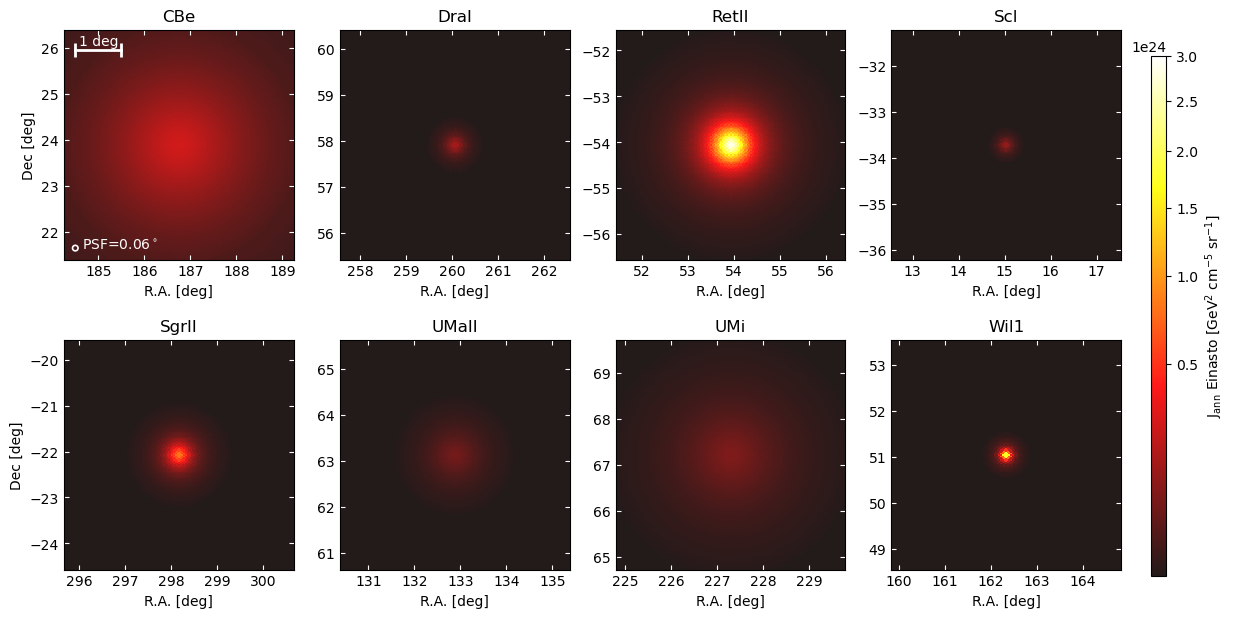

In [20]:
# Create two subplots and unpack the output array immediately
fig, axs = plt.subplots(2, 4, figsize=(15, 8))
#fig.suptitle(r"2D maps for $J_{ann}$ profiles")

counter = 1
for source, ax in zip(dSphNames,axs.flat):
    counter = counter + 1

    normalization_angle = 10;
    jfactor_filename = path2d+'/annihil_'+source+'2D_FOVdiameter10.0deg_nside1024-JFACTOR-Jtot-image.fits'
    spatial_model = TemplateSpatialModel.read(jfactor_filename, normalize=normalization_angle)
    


    # Get the cooordinates of the target and define some skymap extensions
    if (source == dSphNames[0]):
        coordinates = SkyCoord(ra=186.745833 * u.deg, dec=23.904167 * u.deg, frame='icrs')
    else:
        coordinates = SkyCoord.from_name(completeName[counter-2])

    center = (coordinates.ra.value, coordinates.dec.value)
    ra = coordinates.ra.value
    dec = coordinates.dec.value

    rsky = 5
    ra_mv  = ra - rsky
    dec_mv = dec - rsky
    ra_Mv  = ra + rsky
    dec_Mv = dec + rsky

    rzoom = 2.5
    ra_mvz  = ra - rzoom
    dec_mvz = dec - rzoom
    ra_Mvz  = ra + rzoom
    dec_Mvz = dec + rzoom

    alpha=1
    normalization = np.array(spatial_model.map.data) * jfactor_scale(source, profile, alpha)[0]
    print("{:<5} J<({:.1f})={:.1e} ".format(source, alpha, jfactor_scale(source, profile, alpha)[0]))
     
    
    im = ax.imshow(normalization, 
                   interpolation="nearest", 
                   origin="upper",
                   cmap='hot',
                   norm=colors.PowerNorm(gamma=0.5, vmin=1e21, vmax=3e24),
                   extent=(ra_mv,  ra_Mv, dec_mv,  dec_Mv), 
                   alpha=0.9)

    ax.title.set_text(source)

    if counter-1 == 1 or counter-1 == 5:
        ax.set_ylabel(r"Dec [deg]", fontsize=10)
  
    ax.set_xlabel("R.A. [deg]", fontsize=10) 
    ax.locator_params(axis='x', nbins=6)
    ax.locator_params(axis='y', nbins=6)
    
    ax.tick_params(which='both', direction='in', top=True, right=True, color='white')
    
    ax.set_xlim(ra_mvz,  ra_Mvz)
    ax.set_ylim(dec_mvz, dec_Mvz)
       
    radius = alpha_opt[counter-2]
    #radius = alpha_tidal[counter-2]
    circle = Circle(center, radius, facecolor=None, color='blue', fill=False)
    #ax.add_patch(circle)

    # Draw a line
    if counter-1==1:
        psf = Circle((ra_mvz+0.25,dec_mvz+0.25) ,0.06, facecolor=None, color='white', fill=False, lw=1.2)
        ax.text(ra_mvz+0.25+0.15,dec_mvz+0.25-0.02, f'PSF=0.06$^\circ$', fontsize=10, color='white')
        ax.add_patch(psf)
        
        ax.plot([ra_mvz+0.25, ra_mvz+1.25], [dec_Mvz-0.45, dec_Mvz-0.45], 
             color='white', linestyle='-', linewidth=2,
             marker='|', markersize=10, markeredgewidth=2)
        ax.text(ra_mvz+0.75, dec_Mvz-0.35, '1 deg', horizontalalignment='center', fontsize=10, color='white')

     
    
     

cbar_ax = fig.add_axes([0.85, 0.15, 0.01, 0.65])
cb = fig.colorbar(im, cax=cbar_ax)
cb.set_label(r'J$_{{\mathrm{{ann}}}}$ {profile:s} [GeV$^{{2}}$ cm$^{{-5}}$ sr$^{{-1}}$]'.format(profile=profile), color='black')


fig.subplots_adjust(right=0.83, hspace=0.013)

plt.savefig('jfactor_2Dmaps_einasto_combined.png', bbox_inches='tight', pad_inches=0.)